# miseq1/miseq2 shRNA figures: 5' end heatmaps and small RNA metrics

# Re-written my code using Deepseek

Data:
- 33 shRNA samples from the two position files.
- **Round 1**: 21 samples (18 from miseq1 + 3 pLKO samples from miseq2), organized as 7 designs with 3 guide sequences each.
- **Round 2**: 12 individual samples from miseq2.

Figures produced:
1. Heatmaps of 5' end position usage. Each row is a sample and each column is a `start` position. Values are **read count at that position / total reads of the sample x 100**, because total read counts differ between samples.
2. Bar plots of the four per-sample metrics:
   - Small RNA homogeneity
   - Guide heterogeneity
   - Passenger retention
   - Outliers

For Round 1, each design has 3 slim bars, one for each of the 3 guide sequences; the guides are not averaged. For Round 2, each bar is one sample. No statistical tests are performed.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

mpl.rcParams['pdf.fonttype'] = 42
pd.set_option('display.max_columns', 50)

# ----------------------------------------------------------------------
# Input / output
# ----------------------------------------------------------------------
NAME_FILE = Path('/home/kwonschul/projects/shrek/results/240626_miseq1_figure/analysis/papername.txt')
POSITION_FILES = [
    Path('/home/kwonschul/projects/shrek/results/240626_miseq1_figure/annotated/miseq1.shrna.position.txt'),
    Path('/home/kwonschul/projects/shrek/results/240626_miseq2_figure/annotated/miseq2.shrna.position.txt'),
]
OUT_DIR = Path('/home/kwonschul/projects/shrek/deepseek/miseq1_261124fixed')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------------
# Analysis options
# ----------------------------------------------------------------------
GUIDE_WINDOW = 6
PASSENGER_WINDOW = 6
LOG_VMIN = 1.0             # lower limit of the log colour scale (%)
LOG_VMAX = 100.0           # upper limit of the log colour scale (%)
CMAP_NAME = 'PuRd'
UNDER_COLOR = '#f2f2f2'    # colour for 0% and values below LOG_VMIN
SAVE_FIGURES = True
HEATMAP_HEIGHT_FRACTION = 0.50   # shorten heatmap height to 50% of the previous version
ROUND2_WIDTH_FRACTION = 0.70     # shorten Round 2 metric figure width to 70%
ROUND2_FIG_WIDTH = 13.0 * ROUND2_WIDTH_FRACTION

# The first 21 samples in papername.txt are Round 1; the remaining 12 are Round 2.
N_ROUND1 = 21


In [2]:
dfName = pd.read_table(NAME_FILE)
dfShrekNames = dfName[dfName['species'].str.startswith('pShREK')].copy().reset_index(drop=True)

ALL_SAMPLES = dfShrekNames['papername'].tolist()
ROUND1_SAMPLES = ALL_SAMPLES[:N_ROUND1]
ROUND2_SAMPLES = ALL_SAMPLES[N_ROUND1:]
D_PAPER2SPECIES = dict(zip(dfName['papername'], dfName['species']))

print('Total shRNA samples:', len(ALL_SAMPLES))
print('Round 1:', len(ROUND1_SAMPLES))
print('Round 2:', len(ROUND2_SAMPLES))
dfShrekNames.head()


Total shRNA samples: 33
Round 1: 21
Round 2: 12


,species,papername
0,pShREK_mir26a_A1,01Kong-A-1
1,pShREK_mir26a_A2,02Kong-A-2
2,pShREK_mir26a_A3,03Kong-A-3
3,pShREK_mir99a_B4,04Kong-B-4
4,pShREK_mir99a_B5,05Kong-B-5


In [3]:
# Intended 5' end positions (copied from the original notebook)
# 261124 error fixed
dUserIntendedPos = {'pShREK_mir26a_A1':57,
                    'pShREK_mir26a_A2':57,
                    'pShREK_mir26a_A3':57,
                    'pShREK_mir99a_B4':57,
                    'pShREK_mir99a_B5':57,
                    'pShREK_mir99a_B6':57,
                    'pShREK_mir143_C7':95,
                    'pShREK_mir143_C8':95,
                    'pShREK_mir143_C9':95,
                    'pShREK_mir302a_D10':100,
                    'pShREK_mir302a_D11':100,
                    'pShREK_mir302a_D12':100,
                    'pShREK_mir1_E13':97,
                    'pShREK_mir1_E14':97,
                    'pShREK_mir1_E15':97,
                    'pShREK_Kamp2013_F16':96,
                    'pShREK_Kamp2013_F17':96,
                    'pShREK_Kamp2013_F18':96,
                    'pShREK_H0':57,
                    'pShREK_H3':57,
                    'pShREK_Hugu3':57,
                    'pShREK_J0':57,
                    'pShREK_J3':57,
                    'pShREK_K0':57,
                    'pShREK_K3':57,
                    'pShREK_O0':57,
                    'pShREK_O1':57,
                    'pShREK_O2':57,
                    'pShREK_O3':57,
                    'pShREK_Ougu3':57,
                    'pShREK_pLKO_GFP1':32,
                    'pShREK_pLKO_GFP2':32,
                    'pShREK_pLKO_GFP3':32}

dUserPassengerPos = {'pShREK_mir26a_A1':97,
                    'pShREK_mir26a_A2':97,
                    'pShREK_mir26a_A3':97,
                    'pShREK_mir99a_B4':97,
                    'pShREK_mir99a_B5':97,
                    'pShREK_mir99a_B6':97,
                    'pShREK_mir143_C7':57,
                    'pShREK_mir143_C8':57,
                    'pShREK_mir143_C9':57,
                    'pShREK_mir302a_D10':57,
                    'pShREK_mir302a_D11':57,
                    'pShREK_mir302a_D12':57,
                    'pShREK_mir1_E13':57,
                    'pShREK_mir1_E14':57,
                    'pShREK_mir1_E15':57,
                    'pShREK_Kamp2013_F16':57,
                    'pShREK_Kamp2013_F17':57,
                    'pShREK_Kamp2013_F18':57,
                    'pShREK_H0':97,
                    'pShREK_H3':97,
                    'pShREK_Hugu3':97,
                    'pShREK_J0':97,
                    'pShREK_J3':97,
                    'pShREK_K0':97,
                    'pShREK_K3':97,
                    'pShREK_O0':97,
                    'pShREK_O1':97,
                    'pShREK_O2':97,
                    'pShREK_O3':97,
                    'pShREK_Ougu3':97,
                    'pShREK_pLKO_GFP1':0,
                    'pShREK_pLKO_GFP2':0,
                    'pShREK_pLKO_GFP3':0}


In [4]:
# Read the two position files and count reads per (species, start)
frames = []
for path in POSITION_FILES:
    df = pd.read_csv(
        path, sep='\t', header=None, usecols=[0, 1],
        names=['species', 'start'],
        dtype={'species': 'string', 'start': 'int32'},
    )
    counts = (df.groupby(['species', 'start'], sort=False)
                .size()
                .reset_index(name='count'))
    frames.append(counts)

dfCounts = pd.concat(frames, ignore_index=True)
dfCounts = dfCounts.merge(dfShrekNames[['species', 'papername']], on='species', how='left')
assert dfCounts['papername'].notna().all(), 'Some species are missing from papername.txt'

print('Aggregated table:', dfCounts.shape)
print('Samples:', dfCounts['papername'].nunique())
print('Position range:', int(dfCounts['start'].min()), '-', int(dfCounts['start'].max()))
dfCounts.head()


Aggregated table: (723, 4)
Samples: 33
Position range: 0 - 162


,species,start,count,papername
0,pShREK_mir26a_A1,15,1,01Kong-A-1
1,pShREK_mir26a_A1,36,7,01Kong-A-1
2,pShREK_mir26a_A1,37,13,01Kong-A-1
3,pShREK_mir26a_A1,38,41,01Kong-A-1
4,pShREK_mir26a_A1,39,63,01Kong-A-1


In [5]:
# Total reads per sample and percentage per position
dfTotals = (dfCounts.groupby('papername', as_index=False)['count']
            .sum()
            .rename(columns={'count': 'total_count'}))
dfCounts = dfCounts.merge(dfTotals, on='papername', how='left')
dfCounts['percent'] = 100.0 * dfCounts['count'] / dfCounts['total_count']

dfCounts['species'] = dfCounts['papername'].map(D_PAPER2SPECIES)
dfCounts['guide_pos'] = dfCounts['species'].map(dUserIntendedPos)
dfCounts['passenger_pos'] = dfCounts['species'].map(dUserPassengerPos)
assert dfCounts[['guide_pos', 'passenger_pos']].notna().all().all()

print(dfTotals['total_count'].describe())
dfCounts.head()


count       33.000000
mean      9751.333333
std       7654.081557
min       1469.000000
25%       5161.000000
50%       6874.000000
75%      11362.000000
max      32796.000000
Name: total_count, dtype: float64


,species,start,count,papername,total_count,percent,guide_pos,passenger_pos
0,pShREK_mir26a_A1,15,1,01Kong-A-1,24139,0.004143,57,97
1,pShREK_mir26a_A1,36,7,01Kong-A-1,24139,0.028999,57,97
2,pShREK_mir26a_A1,37,13,01Kong-A-1,24139,0.053855,57,97
3,pShREK_mir26a_A1,38,41,01Kong-A-1,24139,0.169850,57,97
4,pShREK_mir26a_A1,39,63,01Kong-A-1,24139,0.260988,57,97


In [6]:
# Four per-sample metrics
dfCounts['in_guide'] = dfCounts['start'].eq(dfCounts['guide_pos'])
dfCounts['in_guide_region'] = (
    (dfCounts['start'] >= dfCounts['guide_pos'] - GUIDE_WINDOW)
    & (dfCounts['start'] <= dfCounts['guide_pos'] + GUIDE_WINDOW)
)
dfCounts['in_passenger_region'] = (
    (dfCounts['start'] >= dfCounts['passenger_pos'] - PASSENGER_WINDOW)
    & (dfCounts['start'] <= dfCounts['passenger_pos'] + PASSENGER_WINDOW)
)

dfCounts['count_guide'] = dfCounts['count'] * dfCounts['in_guide'].astype(int)
dfCounts['count_guide_region'] = dfCounts['count'] * dfCounts['in_guide_region'].astype(int)
dfCounts['count_passenger_region'] = dfCounts['count'] * dfCounts['in_passenger_region'].astype(int)

dfMetrics = (dfCounts
    .groupby(['papername', 'species', 'guide_pos', 'passenger_pos'], as_index=False)
    .agg(total_count=('count', 'sum'),
         guide_count=('count_guide', 'sum'),
         guide_region_count=('count_guide_region', 'sum'),
         passenger_region_count=('count_passenger_region', 'sum')))

def percent_or_nan(numerator, denominator):
    numerator = np.asarray(numerator, dtype=float)
    denominator = np.asarray(denominator, dtype=float)
    out = np.full(numerator.shape, np.nan)
    np.divide(numerator, denominator, out=out, where=denominator > 0)
    return out * 100.0

dfMetrics['homogeneity_percent'] = percent_or_nan(
    dfMetrics['guide_count'], dfMetrics['total_count'])
dfMetrics['heterogeneity_percent'] = percent_or_nan(
    dfMetrics['guide_region_count'] - dfMetrics['guide_count'],
    dfMetrics['guide_region_count'])
dfMetrics['passenger_retention_percent'] = percent_or_nan(
    dfMetrics['passenger_region_count'],
    dfMetrics['guide_region_count'] + dfMetrics['passenger_region_count'])
dfMetrics['outlier_percent'] = percent_or_nan(
    dfMetrics['total_count'] - dfMetrics['guide_region_count'] - dfMetrics['passenger_region_count'],
    dfMetrics['total_count'])

dfMetrics['round'] = np.where(dfMetrics['papername'].isin(ROUND1_SAMPLES), 'Round 1', 'Round 2')
dfMetrics['group'] = np.where(
    dfMetrics['round'] == 'Round 1',
    dfMetrics['papername'].apply(lambda x: '-'.join(x.split('-')[:-1])[2:]),
    dfMetrics['papername'])

# Guide number within each Round 1 design (1st, 2nd, 3rd guide by sample name)
dfMetrics['guide_index'] = np.nan
mask_round1 = dfMetrics['round'] == 'Round 1'
guide_order = (dfMetrics.loc[mask_round1]
               .sort_values(['group', 'papername'])
               .groupby('group')
               .cumcount())
dfMetrics.loc[mask_round1, 'guide_index'] = guide_order

dfMetrics = dfMetrics.set_index('papername').reindex(ALL_SAMPLES).reset_index()
dfMetrics.head()


,papername,species,guide_pos,passenger_pos,total_count,guide_count,guide_region_count,passenger_region_count,homogeneity_percent,heterogeneity_percent,passenger_retention_percent,outlier_percent,round,group,guide_index
0,01Kong-A-1,pShREK_mir26a_A1,57,97,24139,22116,22699,1149,91.619371,2.568395,4.818014,1.205518,Round 1,Kong-A,0.0
1,02Kong-A-2,pShREK_mir26a_A2,57,97,12920,11264,11760,831,87.182663,4.217687,6.599952,2.546440,Round 1,Kong-A,1.0
2,03Kong-A-3,pShREK_mir26a_A3,57,97,32796,27928,29304,3200,85.156726,4.695605,9.844942,0.890352,Round 1,Kong-A,2.0
3,04Kong-B-4,pShREK_mir99a_B4,57,97,11362,10135,10382,613,89.200845,2.379118,5.575261,3.230065,Round 1,Kong-B,0.0
4,05Kong-B-5,pShREK_mir99a_B5,57,97,7585,6804,7113,124,89.703362,4.344159,1.713417,4.588003,Round 1,Kong-B,1.0


In [7]:
def trim_trailing_zero_columns(matrix):
    """Remove trailing columns that are zero in every row."""
    has_data = (matrix.values > 0).any(axis=0)
    if has_data.any():
        last = np.where(has_data)[0][-1]
        return matrix.iloc[:, :last + 1]
    return matrix


def draw_position_heatmap(matrix, title, output_stem, divider_after=None):
    """Heatmap: rows = samples, columns = 5' end positions, colour = % of reads."""
    n_rows, n_cols = matrix.shape
    fig_height = HEATMAP_HEIGHT_FRACTION * max(3.5, 0.23 * n_rows + 1.6)
    fig, ax = plt.subplots(figsize=(12, fig_height))

    cmap = plt.get_cmap(CMAP_NAME).copy()
    cmap.set_under(UNDER_COLOR)
    cmap.set_bad(UNDER_COLOR)

    values = np.ma.masked_where(matrix.values <= 0, matrix.values)
    norm = LogNorm(vmin=LOG_VMIN, vmax=LOG_VMAX, clip=False)

    im = ax.imshow(values, aspect='auto', interpolation='nearest',
                   cmap=cmap, norm=norm, origin='upper')

    ax.set_yticks(np.arange(n_rows))
    ax.set_yticklabels(matrix.index, fontsize=7)
    ax.set_ylabel('Sample', fontsize=9)

    xtick_step = 10
    ax.set_xticks(np.arange(0, n_cols, xtick_step))
    ax.set_xticklabels(matrix.columns[::xtick_step], fontsize=7)
    ax.set_xlabel("5' end position of small RNA (rstart, nt)", fontsize=9)

    ax.set_title(title, fontsize=11, pad=8)

    if divider_after is not None:
        ax.axhline(divider_after - 0.5, color='white', linewidth=2.5)

    cbar = fig.colorbar(
        im, ax=ax, fraction=0.03, pad=0.02,
    )
    cbar.set_label('% of total reads (log scale; <1 = grey)', fontsize=8)
    colorbar_ticks = [1, 2, 5, 10, 20, 50, 100]
    cbar.set_ticks(colorbar_ticks)
    cbar.set_ticklabels(['{:g}'.format(t) for t in colorbar_ticks])
    cbar.ax.tick_params(labelsize=7)

    fig.tight_layout()

    if SAVE_FIGURES:
        for ext in ['pdf', 'png']:
            fig.savefig(OUT_DIR / '{}.{}'.format(output_stem, ext),
                        dpi=300, bbox_inches='tight')
    return fig


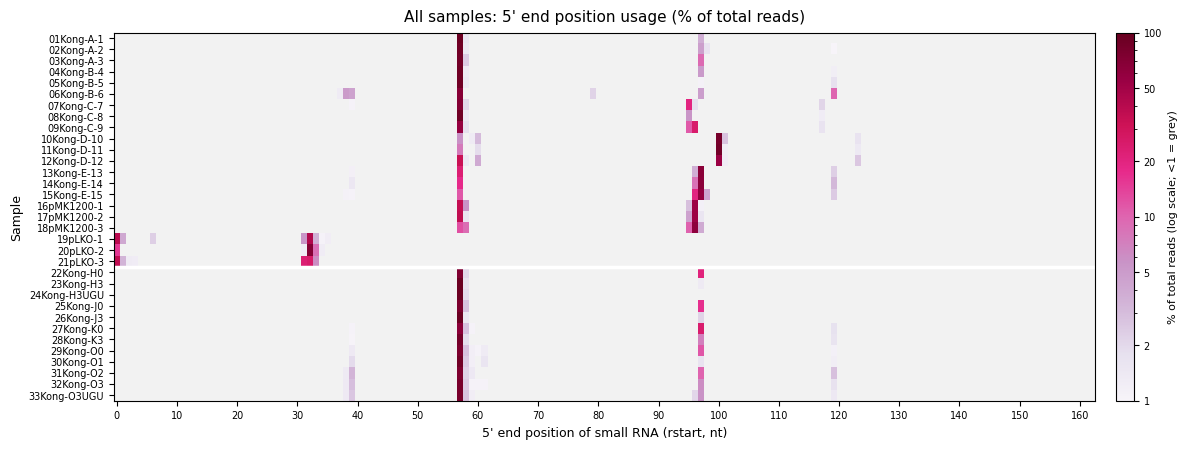

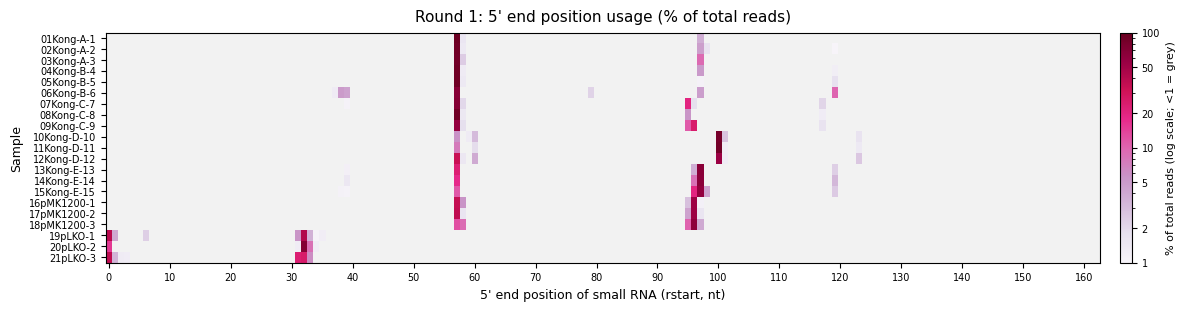

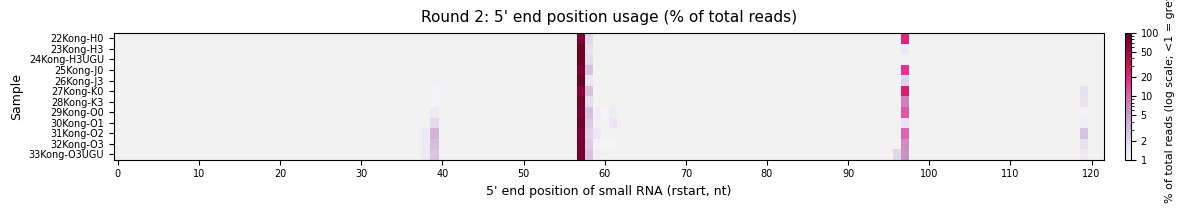

Heatmap matrices: (33, 163) (21, 163) (12, 122)


In [8]:
# Build the percentage matrices and draw the heatmaps
all_positions = np.arange(0, int(dfCounts['start'].max()) + 1)

matAll = (dfCounts.pivot(index='papername', columns='start', values='percent')
          .reindex(index=ALL_SAMPLES, columns=all_positions)
          .fillna(0.0))
matAll = trim_trailing_zero_columns(matAll)

matR1 = trim_trailing_zero_columns(matAll.loc[ROUND1_SAMPLES])
matR2 = trim_trailing_zero_columns(matAll.loc[ROUND2_SAMPLES])

figAll = draw_position_heatmap(
    matAll,
    'All samples: 5\' end position usage (% of total reads)',
    'heatmap_reads_all_samples',
    divider_after=N_ROUND1)
plt.show()

figR1 = draw_position_heatmap(
    matR1,
    'Round 1: 5\' end position usage (% of total reads)',
    'heatmap_reads_round1')
plt.show()

figR2 = draw_position_heatmap(
    matR2,
    'Round 2: 5\' end position usage (% of total reads)',
    'heatmap_reads_round2')
plt.show()

plt.close(figAll)
plt.close(figR1)
plt.close(figR2)

print('Heatmap matrices:', matAll.shape, matR1.shape, matR2.shape)


In [9]:
METRIC_SPECS = [
    ('homogeneity_percent', 'Small RNA homogeneity'),
    ('heterogeneity_percent', 'Guide heterogeneity'),
    ('passenger_retention_percent', 'Passenger retention'),
    ('outlier_percent', 'Outliers'),
]

GROUP_ORDER = ['Kong-A', 'Kong-B', 'Kong-C', 'Kong-D', 'Kong-E', 'pMK1200', 'pLKO']

# Round 1: Kong-A is red (emphasized), Kong-B-E are grey-based,
# pMK1200 and pLKO are distinct highlighted controls.
DESIGN_COLORS = {
    'Kong-A': '#cb181d',   # red, emphasized
    'Kong-B': '#7f7f7f',   # neutral grey
    'Kong-C': '#7f8c8d',   # blue-grey
    'Kong-D': '#8d7f7f',   # warm grey
    'Kong-E': '#7f8d7f',   # green-grey
    'pMK1200': '#e6ab02',  # gold control
    'pLKO': '#1f78b4',     # blue control
}

# Round 2: 26Kong-J3 is red; the other samples use different grey shades.
ROUND2_EMPHASIS_SAMPLE = '26Kong-J3'
ROUND2_GRAY_COLORS = ['#404040', '#4d4d4d', '#5a5a5a', '#676767',
                      '#747474', '#818181', '#8e8e8e', '#9b9b9b',
                      '#a8a8a8', '#b5b5b5', '#c2c2c2']


def format_metric_value(value):
    """One decimal for values >=1%; two decimals for values <1%."""
    return '{:.1f}%'.format(value) if value >= 1 else '{:.2f}%'.format(value)


def blend_color(color, other, fraction):
    """Blend a colour towards white or black."""
    c = np.array(mpl.colors.to_rgb(color))
    o = np.array(mpl.colors.to_rgb(other))
    return tuple(c * (1.0 - fraction) + o * fraction)


def get_guide_colors(group):
    """Three similar but distinct shades for the 3 guides of one design."""
    base = DESIGN_COLORS[group]
    return [
        blend_color(base, 'white', 0.45),   # Guide 1: lightest
        base,                                # Guide 2: base colour
        blend_color(base, 'black', 0.25),   # Guide 3: darkest
    ]


def style_metric_axis(ax, title, xlabels, rotation=0):
    ax.set_title(title, fontsize=11, pad=8)
    ax.set_ylabel('Percentage (%)', fontsize=9)
    ax.set_xlabel('')
    ax.set_xticks(np.arange(len(xlabels)))
    ha_value = 'right' if rotation == 45 else 'center'
    ax.set_xticklabels(xlabels, rotation=rotation, ha=ha_value, fontsize=8)
    ax.tick_params(axis='y', labelsize=8)
    ax.yaxis.grid(True, color='#e6e6e6', linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def draw_round1_barplots(df_data, output_stem):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    df_data = df_data.set_index('papername').reindex(ROUND1_SAMPLES).reset_index()

    n_guides = 3
    bar_width = 0.24
    guide_offsets = np.linspace(-0.26, 0.26, n_guides)

    for ax, (metric, title) in zip(axes.ravel(), METRIC_SPECS):
        x_centers = np.arange(len(GROUP_ORDER))
        y_top = df_data[metric].max() * 1.25

        for group_index, group in enumerate(GROUP_ORDER):
            group_data = (df_data[df_data['group'] == group]
                          .sort_values('guide_index'))
            group_colors = get_guide_colors(group)

            for guide_index, (_, row) in enumerate(group_data.iterrows()):
                if guide_index >= n_guides:
                    continue
                value = row[metric]
                xpos = group_index + guide_offsets[guide_index]

                ax.bar(xpos, value, width=bar_width,
                       color=group_colors[guide_index],
                       edgecolor='#404040', linewidth=0.5, zorder=2)

                # Place the value clearly above the bar (3 points gap).
                ax.annotate(format_metric_value(value),
                            xy=(xpos, value), xytext=(0, 3),
                            textcoords='offset points',
                            ha='center', va='bottom',
                            rotation=90, fontsize=5.2, zorder=3)

        ax.set_ylim(0, y_top)
        style_metric_axis(ax, title, GROUP_ORDER, rotation=0)

    fig.text(0.5, 0.92,
             'Within each design: Guide 1 (lightest) -> Guide 3 (darkest)\n'
             'Kong-A = red; Kong-B-E = grey; pMK1200 and pLKO = controls',
             ha='center', va='center', fontsize=8.2, linespacing=1.2)
    fig.suptitle('Round 1 metrics (3 guide sequences per design; values above bars)',
                 fontsize=12, y=0.985)
    fig.tight_layout(rect=[0, 0, 1, 0.90])

    if SAVE_FIGURES:
        for ext in ['pdf', 'png']:
            fig.savefig(OUT_DIR / '{}.{}'.format(output_stem, ext),
                        dpi=300, bbox_inches='tight')
    return fig


def draw_round2_barplots(df_data, output_stem):
    fig, axes = plt.subplots(2, 2, figsize=(ROUND2_FIG_WIDTH, 8))
    df_data = df_data.set_index('papername').reindex(ROUND2_SAMPLES).reset_index()

    sample_names = df_data['papername'].tolist()
    bar_colors = []
    edge_colors = []
    gray_index = 0
    for sample in sample_names:
        if sample == ROUND2_EMPHASIS_SAMPLE:
            bar_colors.append('#cb181d')
            edge_colors.append('#67000d')
        else:
            bar_colors.append(ROUND2_GRAY_COLORS[gray_index % len(ROUND2_GRAY_COLORS)])
            edge_colors.append('#333333')
            gray_index += 1

    for ax, (metric, title) in zip(axes.ravel(), METRIC_SPECS):
        vals = df_data[metric].values
        x = np.arange(len(vals))

        ax.bar(x, vals, color=bar_colors, edgecolor=edge_colors,
               linewidth=0.6, zorder=2)

        for i, value in enumerate(vals):
            ax.annotate(format_metric_value(value),
                        xy=(i, value), xytext=(0, 3),
                        textcoords='offset points',
                        ha='center', va='bottom',
                        rotation=0, fontsize=5.5, zorder=3)

        ax.set_ylim(0, np.nanmax(vals) * 1.22)
        style_metric_axis(ax, title, sample_names, rotation=90)

    fig.suptitle('Round 2 metrics (individual samples; 26Kong-J3 in red)',
                 fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.95])

    if SAVE_FIGURES:
        for ext in ['pdf', 'png']:
            fig.savefig(OUT_DIR / '{}.{}'.format(output_stem, ext),
                        dpi=300, bbox_inches='tight')
    return fig


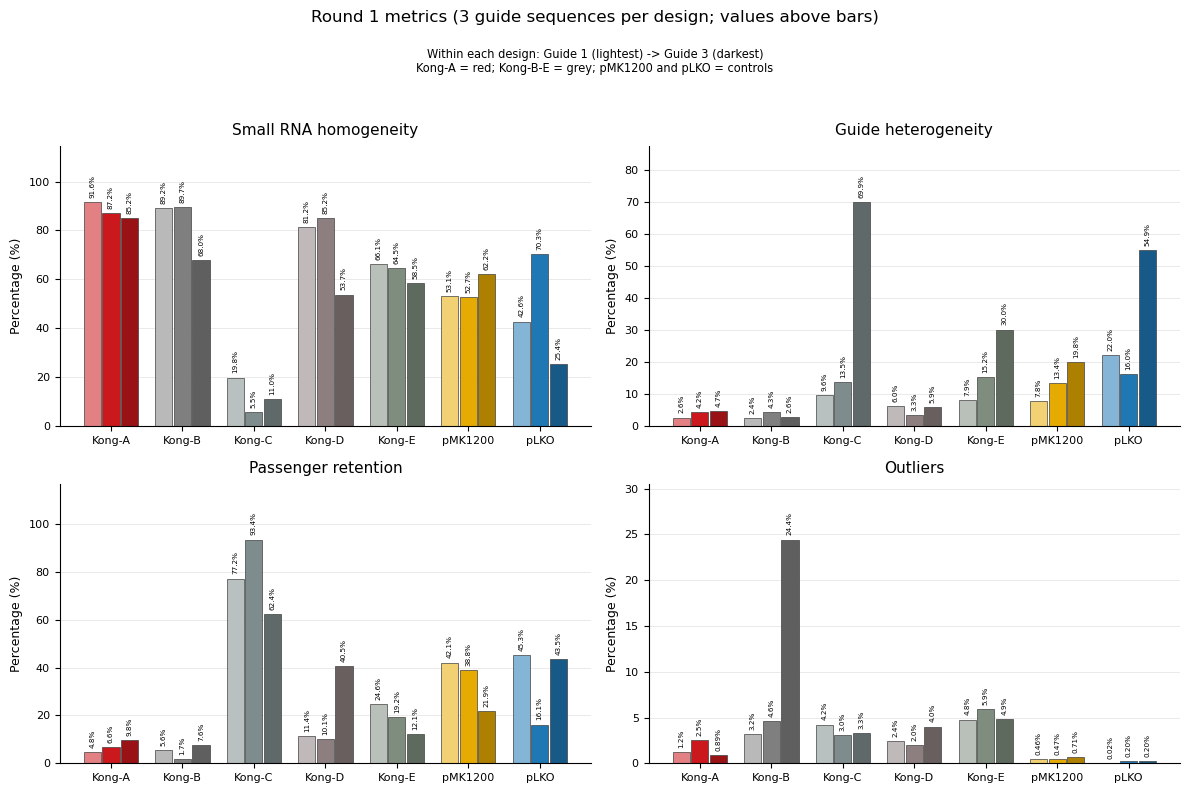

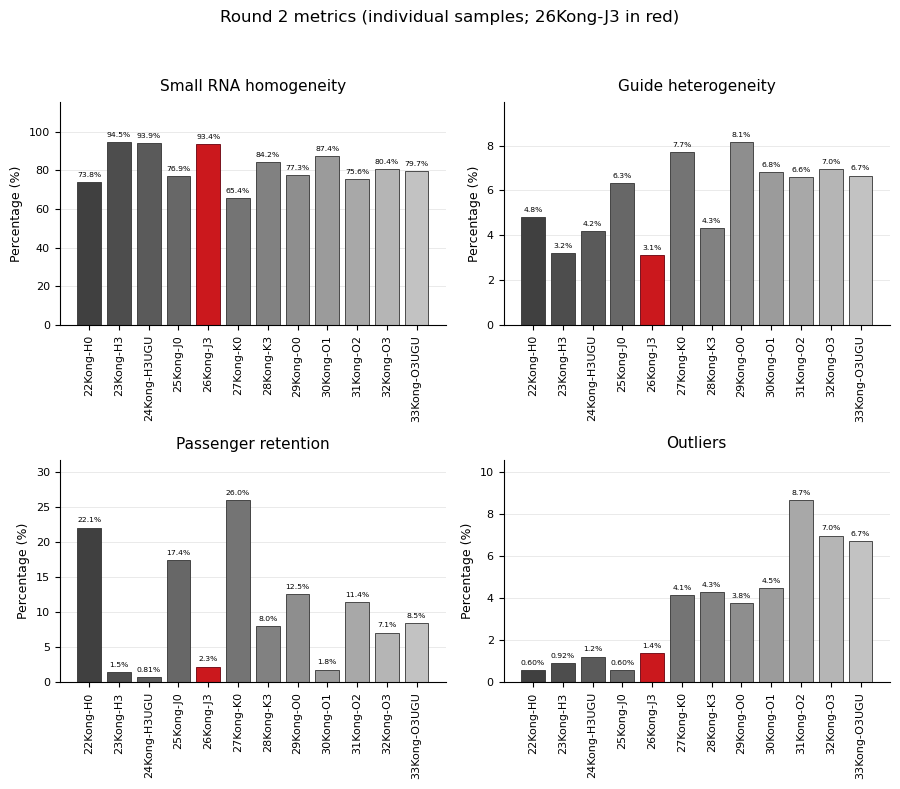

In [10]:
figR1Bar = draw_round1_barplots(dfMetrics[dfMetrics['round'] == 'Round 1'],
                                  'metrics_round1_barplots')
plt.show()

figR2Bar = draw_round2_barplots(dfMetrics[dfMetrics['round'] == 'Round 2'],
                                  'metrics_round2_barplots')
plt.show()

plt.close(figR1Bar)
plt.close(figR2Bar)


In [11]:
# Save the per-sample metrics and heatmap matrices as CSV (no Excel files)
if SAVE_FIGURES:
    dfMetrics.to_csv(OUT_DIR / 'miseq12_metrics_per_sample.csv', index=False)
    matAll.to_csv(OUT_DIR / 'heatmap_percent_all_samples.csv')
    matR1.to_csv(OUT_DIR / 'heatmap_percent_round1.csv')
    matR2.to_csv(OUT_DIR / 'heatmap_percent_round2.csv')
    print('Saved figures and tables to {}'.format(OUT_DIR))

dfMetrics.head()


Saved figures and tables to /home/kwonschul/projects/shrek/deepseek/miseq1_261124fixed


,papername,species,guide_pos,passenger_pos,total_count,guide_count,guide_region_count,passenger_region_count,homogeneity_percent,heterogeneity_percent,passenger_retention_percent,outlier_percent,round,group,guide_index
0,01Kong-A-1,pShREK_mir26a_A1,57,97,24139,22116,22699,1149,91.619371,2.568395,4.818014,1.205518,Round 1,Kong-A,0.0
1,02Kong-A-2,pShREK_mir26a_A2,57,97,12920,11264,11760,831,87.182663,4.217687,6.599952,2.546440,Round 1,Kong-A,1.0
2,03Kong-A-3,pShREK_mir26a_A3,57,97,32796,27928,29304,3200,85.156726,4.695605,9.844942,0.890352,Round 1,Kong-A,2.0
3,04Kong-B-4,pShREK_mir99a_B4,57,97,11362,10135,10382,613,89.200845,2.379118,5.575261,3.230065,Round 1,Kong-B,0.0
4,05Kong-B-5,pShREK_mir99a_B5,57,97,7585,6804,7113,124,89.703362,4.344159,1.713417,4.588003,Round 1,Kong-B,1.0


### Notes

- **Small RNA homogeneity** = reads at `GUIDE_POS` / total reads x 100.
- **Guide heterogeneity** = (reads in `GUIDE_POS +/-6 nt` - reads at `GUIDE_POS`) / reads in `GUIDE_POS +/-6 nt` x 100.
- **Passenger retention** = reads in `PASSENGER_POS +/-6 nt` / (guide-window + passenger-window reads) x 100.
- **Outliers** = (total reads - guide-window reads - passenger-window reads) / total reads x 100.

- `GUIDE_POS` and `PASSENGER_POS` are the intended positions from the original notebook. For pLKO, the passenger position is 0.
